In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append('..')

from src.embedder import ProfileEmbedder
from src.matcher import ValuesMatcher

In [2]:
profiles = ProfileEmbedder.load_profiles("../data/profiles.json")
embedder = ProfileEmbedder()
embeddings = embedder.embed_all_profiles(profiles)
matcher = ValuesMatcher(embeddings, profiles)
print("Ready")

Loading embedding model: sentence-transformers/all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model loaded successfully
Embedding 15 profiles...
  Embedded user_001 (Amara)
  Embedded user_002 (Daniel)
  Embedded user_003 (Sofia)
  Embedded user_004 (Marcus)
  Embedded user_005 (Lena)
  Embedded user_006 (James)
  Embedded user_007 (Nadia)
  Embedded user_008 (Kofi)
  Embedded user_009 (Priya)
  Embedded user_010 (Emmanuel)
  Embedded user_011 (Claire)
  Embedded user_012 (Yusuf)
  Embedded user_013 (Hana)
  Embedded user_014 (Ibrahim)
  Embedded user_015 (Zoe)
All profiles embedded successfully
Ready


In [3]:
similarity_matrix = matcher.get_full_similarity_matrix()
names = [p["name"] for p in profiles]
print("Matrix shape:", similarity_matrix.shape)
print("Done")

Matrix shape: (15, 15)
Done


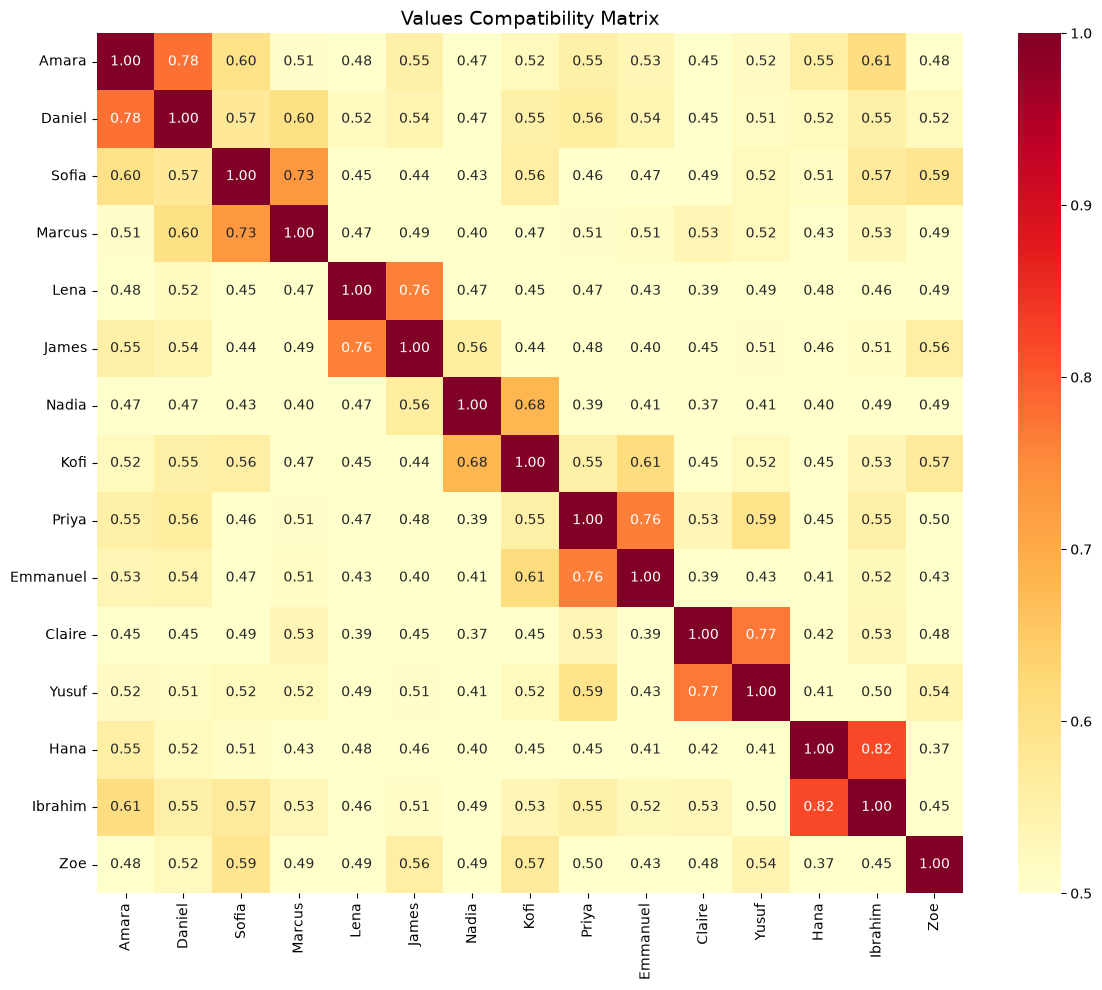

In [4]:
plt.figure(figsize=(12, 10))
sns.heatmap(
    similarity_matrix,
    xticklabels=names,
    yticklabels=names,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0.5,
    vmax=1.0
)
plt.title("Values Compatibility Matrix", fontsize=14)
plt.tight_layout()
plt.savefig("compatibility_matrix.png", dpi=150)
plt.show()

In [5]:
user_id = "user_001"
profile = next(p for p in profiles if p["id"] == user_id)
matches = matcher.get_top_matches(user_id, top_n=3)

print(f"Profile: {profile['name']}")
print(f"Values: {profile['values']}\n")

for match in matches:
    print(f"Match: {match['name']} — Score: {match['score']}")
    print(f"Their values: {match['values']}")
    print()

Profile: Amara
Values: ['I believe children thrive with consistent routines and clear boundaries', 'Financial stability before starting a family is non-negotiable for me', 'I want my children to have a strong cultural and religious foundation']

Match: Daniel — Score: 0.7778
Their values: ['Structure and predictability are essential for raising confident children', 'I prioritize building financial security before expanding my family', 'Passing down cultural heritage and faith to my children matters deeply to me']

Match: Ibrahim — Score: 0.6104
Their values: ['Spirituality and religious identity give children a strong sense of self', 'I want my children raised in an active faith community', 'Religious practice should be woven into daily family life']

Match: Sofia — Score: 0.5989
Their values: ['Children need freedom to explore and make mistakes to grow', 'I believe in gentle parenting without strict rules or punishments', 'Adventure and new experiences should be central to family life